# ML Project 1

## Imports and Setup

In [70]:
import importlib
import matplotlib.pyplot as plt
import numpy as np

import evals
import implementations
import preprocessing

importlib.reload(evals)
importlib.reload(implementations)
importlib.reload(preprocessing)

from evals import accuracy_from_model, accuracy_from_predictions, f1_score
from helpers import load_csv_data, create_csv_submission
from implementations import negative_log_likelihood, reg_logistic_regression, sigmoid, sgd_for_svm_demo
from preprocessing import add_bias, balance_dataset, train_val_split

In [71]:
SEED = 43
np.random.seed(SEED)

## Loading the data

In [72]:
path = "data/dataset"

x_train_data, x_test_data, y_train_data, train_ids, test_ids = load_csv_data(path)

## Cleaning the data
Delete any columns which have are completely empty, fill in missing values.

In [73]:
HEADER = """_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,DIABETE3,DIABAGE2,SEX,MARITAL,EDUCA,RENTHOM1,NUMHHOL2,NUMPHON2,CPDEMO1,VETERAN3,EMPLOY1,CHILDREN,INCOME2,INTERNET,WEIGHT2,HEIGHT3,PREGNANT,QLACTLM2,USEEQUIP,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,EXERANY2,EXRACT11,EXEROFT1,EXERHMM1,EXRACT21,EXEROFT2,EXERHMM2,STRENGTH,LMTJOIN3,ARTHDIS2,ARTHSOCL,JOINPAIN,SEATBELT,FLUSHOT6,FLSHTMY2,IMFVPLAC,PNEUVAC3,HIVTST6,HIVTSTD3,WHRTST10,PDIABTST,PREDIAB1,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,CAREGIV1,CRGVREL1,CRGVLNG1,CRGVHRS1,CRGVPRB1,CRGVPERS,CRGVHOUS,CRGVMST2,CRGVEXPT,VIDFCLT2,VIREDIF3,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,CIMEMLOS,CDHOUSE,CDASSIST,CDHELP,CDSOCIAL,CDDISCUS,WTCHSALT,LONGWTCH,DRADVISE,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,HAREHAB1,STREHAB1,CVDASPRN,ASPUNSAF,RLIVPAIN,RDUCHART,RDUCSTRK,ARTTODAY,ARTHWGT,ARTHEXER,ARTHEDU,TETANUS,HPVADVC2,HPVADSHT,SHINGLE2,HADMAM,HOWLONG,HADPAP2,LASTPAP2,HPVTEST,HPLSTTST,HADHYST2,PROFEXAM,LENGEXAM,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,PCPSAAD2,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,PCPSADE1,PCDMDECN,SCNTMNY1,SCNTMEL1,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,SXORIENT,TRNSGNDR,RCSGENDR,RCSRLTN2,CASTHDX2,CASTHNO2,EMTSUPRT,LSATISFY,ADPLEASR,ADDOWN,ADSLEEP,ADENERGY,ADEAT1,ADFAIL,ADTHINK,ADMOVE,MISTMNT,ADANXEV,QSTVER,QSTLANG,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_CHISPNC,_CRACE1,_CPRACE,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT,_RFHLTH,_HCVU651,_RFHYPE5,_CHOLCHK,_RFCHOL,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACE_G1,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,BMI5CAT,RFBMI5,CHLDCNT,EDUCAG,INCOMG,SMOKER3,RFSMOK3,DRNKANY5,DROCDY3,RFBING5,DRNKWEK,RFDRHV5,FTJUDA1,FRUTDA1,BEANDAY,GRENDAY,ORNGDAY,VEGEDA1,MISFRTN,MISVEGN,FRTRESP,VEGRESP,FRUTSUM,VEGESUM,FRTLT1,VEGLT1,FRT16,VEG23,FRUITEX,VEGETEX,TOTINDA,METVL11,METVL21,MAXVO2,FC60,ACTIN11,ACTIN21,PADUR1,PADUR2,PAFREQ1,PAFREQ2,MINAC11,MINAC21,STRFREQ,PAMISS1,PAMIN11,PAMIN21,PA1MIN,PAVIG11,PAVIG21,PA1VIGM,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3""".split(
    ","
)
IDX = {n: i for i, n in enumerate(HEADER)}

# ---- codes that mean "don't know / refused" -> NaN (from the codebook) ----
DK = {}
for n in [
    "HLTHPLN1",
    "MEDCOST",
    "BPMEDS",
    "BLOODCHO",
    "TOLDHI2",
    "CVDSTRK3",
    "ASTHMA3",
    "ASTHNOW",
    "CHCSCNCR",
    "CHCOCNCR",
    "CHCCOPD1",
    "HAVARTH3",
    "ADDEPEV2",
    "CHCKIDNY",
    "VETERAN3",
    "INTERNET",
    "QLACTLM2",
    "USEEQUIP",
    "BLIND",
    "DECIDE",
    "DIFFWALK",
    "DIFFDRES",
    "DIFFALON",
    "SMOKE100",
    "SMOKDAY2",
    "STOPSMK2",
    "USENOW3",
    "EXERANY2",
    "FLUSHOT6",
    "PNEUVAC3",
    "HIVTST6",
    "PREGNANT",
    "LMTJOIN3",
    "ARTHDIS2",
    "GENHLTH",
    "PERSDOC2",
    "CHECKUP1",
    "CHOLCHK",
    "BPHIGH4",
    "DIABETE3",
    "RENTHOM1",
    "SEATBELT",
]:
    DK[n] = [7, 9]
DK.update(
    {
        "EDUCA": [9],
        "MARITAL": [9],
        "EMPLOY1": [9],
        "INCOME2": [77, 99],
        "LASTSMK2": [77, 99],
        "PHYSHLTH": [77, 99],
        "MENTHLTH": [77, 99],
        "POORHLTH": [77, 99],
        "DRNK3GE5": [77, 99],
        "AVEDRNK2": [77, 99],
        "MAXDRNKS": [77, 99],
        "JOINPAIN": [77, 99],
        "CHILDREN": [99],
        "DIABAGE2": [98, 99],
        "WEIGHT2": [7777, 9999],
        "HEIGHT3": [7777, 9999],
    }
)
for n in [
    "ALCDAY5",
    "FRUITJU1",
    "FRUIT1",
    "FVBEANS",
    "FVGREEN",
    "FVORANG",
    "VEGETAB1",
    "EXEROFT1",
    "EXEROFT2",
    "STRENGTH",
    "EXERHMM1",
    "EXERHMM2",
]:
    DK[n] = [777, 999]
# CDC-calculated columns where 9 (or 14, 3, 77/99) = don't know / refused / missing
for n in [
    "_RFHLTH",
    "_HCVU651",
    "_RFHYPE5",
    "_CHOLCHK",
    "_RFCHOL",
    "_LTASTH1",
    "_CASTHM1",
    "_ASTHMS1",
    "_RACE",
    "_RACEG21",
    "_RACEGR3",
    "_HISPANC",
    "_PACAT1",
    "_PAINDX1",
    "_PA150R2",
    "_PA300R2",
    "_PA30021",
    "_PASTRNG",
    "_PAREC1",
    "_PASTAE1",
    "_LMTACT1",
    "_LMTWRK1",
    "_LMTSCL1",
    "_RFSEAT2",
    "_RFSEAT3",
    "_FLSHOT6",
    "_PNEUMO2",
    "_AIDTST3",
    "RFBMI5",
    "CHLDCNT",
    "EDUCAG",
    "INCOMG",
    "SMOKER3",
    "RFSMOK3",
    "DRNKANY5",
    "RFBING5",
    "RFDRHV5",
    "TOTINDA",
    "PAMISS1",
]:
    DK[n] = [9]
DK.update({"_AGEG5YR": [14], "_AGE65YR": [3], "_PRACE1": [77, 99], "_MRACE1": [77, 99]})

# ---- columns that are not features: ids, admin, weights, phone-intro, raw weight/height
DROP = {
    "Id",
    "FMONTH",
    "IDATE",
    "IMONTH",
    "IDAY",
    "IYEAR",
    "DISPCODE",
    "SEQNO",
    "_PSU",
    "QSTVER",
    "QSTLANG",
    "MSCODE",
    "_STSTR",
    "_STRWT",
    "_RAWRAKE",
    "_WT2RAKE",
    "_CHISPNC",
    "_CLLCPWT",
    "_DUALUSE",
    "_DUALCOR",
    "_LLCPWT",
    "CTELENUM",
    "PVTRESD1",
    "COLGHOUS",
    "STATERES",
    "CELLFON3",
    "LADULT",
    "NUMADULT",
    "NUMMEN",
    "NUMWOMEN",
    "CTELNUM1",
    "CELLFON2",
    "CADULT",
    "PVTRESD2",
    "CCLGHOUS",
    "CSTATE",
    "LANDLINE",
    "HHADULT",
    "NUMHHOL2",
    "NUMPHON2",
    "CPDEMO1",
    "WEIGHT2",
    "HEIGHT3",
    "HTIN4",
}

NOMINAL = {
    "_STATE",
    "EXRACT11",
    "EXRACT21",
    "IMFVPLAC",
    "WHRTST10",
    "MARITAL",
    "EMPLOY1",
    "RENTHOM1",
    "_RACE",
    "_HISPANC",
}

In [74]:
def standardise(X, names, params=None):
    X = np.array(X, dtype=np.float64)

    if params is None:
        # Select continuous numerical columns
        # A column is treated as continuous if at least 10 unique values exist or it has non-integer values, otherwise it is treated as categorical / ordinal
        idx = [
            j
            for j, n in enumerate(names)
            if n not in NOMINAL
            and (
                len(np.unique(X[:, j])) > 10 or not np.all(X[:, j] == np.round(X[:, j]))
            )
        ]

        # Compute mean and standard deviation along columns
        mean = np.mean(X[:, idx], axis=0)
        std = np.std(X[:, idx], axis=0)
        std[std == 0] = 1.0  # Avoid division by zero

        params = (idx, mean, std)
        print(f"standardising {len(idx)} of {X.shape[1]} columns")

    # Vectorized Z-score standardization: (X - mean) / std
    idx, mean, std = params
    X[:, idx] = (X[:, idx] - mean) / std

    return X.astype(np.float32), params


def _freq(v, factors, zero=(), lt1=None):
    """Frequency codes (1xx/2xx/3xx) -> times per 30 days."""
    out = np.full_like(v, np.nan)
    with np.errstate(invalid="ignore"):
        h, r = v // 100, v % 100
        for k, f in factors.items():
            m = (h == k) & (r > 0)
            out[m] = r[m] * f
        out[np.isin(v, zero)] = 0
        if lt1 is not None:
            out[v == 300] = lt1
    return out


def clean_brfss(X, keep=None, max_missing=0.5):
    """X: 2-D array, columns exactly as in HEADER, blanks = np.nan.
    Returns (Xc, names, dropped): cleaned array, its column names, {dropped name: reason}.
    """
    X = np.array(X, dtype=np.float64)  # copy
    assert X.shape[1] == len(
        HEADER
    ), f"expected {len(HEADER)} columns, got {X.shape[1]}"
    col = lambda n: X[:, IDX[n]]  # view: edits write into X

    # 1. don't know / refused -> NaN
    for n, codes in DK.items():
        if n in IDX:
            c = col(n)
            c[np.isin(c, codes)] = np.nan
    c = col("WTKG3")
    c[c > 300] = np.nan
    c = col("HTM4")
    c[c > 2.5] = np.nan
    c = col("DRNKWEK")
    c[c >= 999] = np.nan

    # 2. 88 = "None" is a real answer -> 0
    for n in ["PHYSHLTH", "MENTHLTH", "POORHLTH", "CHILDREN", "DRNK3GE5"]:
        c = col(n)
        c[c == 88] = 0

    # 3. blanks caused only by skip logic -> the implied answer
    def fill(target, cond, value):
        with np.errstate(invalid="ignore"):
            m = np.isnan(col(target)) & cond
        col(target)[m] = value

    fill("BPMEDS", col("BPHIGH4") != 1, 2)  # no high BP -> not on BP meds
    fill("ASTHNOW", col("ASTHMA3") == 2, 2)  # never had asthma -> no asthma now
    fill("POORHLTH", (col("PHYSHLTH") == 0) & (col("MENTHLTH") == 0), 0)
    fill("SMOKDAY2", col("SMOKE100") == 2, 3)  # never smoked -> "not at all"
    fill("STOPSMK2", col("SMOKE100") == 2, 2)
    fill("PREGNANT", (col("SEX") == 1) | (col("_AGE80") > 44), 2)  # men / over 44 -> no
    for t in ["AVEDRNK2", "DRNK3GE5", "MAXDRNKS"]:
        fill(t, col("ALCDAY5") == 888, 0)  # no drinks in past 30 days
    for t in ["EXEROFT1", "EXERHMM1", "EXEROFT2", "EXERHMM2", "STRENGTH"]:
        fill(t, col("EXERANY2") == 2, 0)  # no exercise -> 0

    # 4. frequency / time codes -> numbers (times per 30 days; minutes)
    fv = {1: 30, 2: 30 / 7, 3: 1}
    for n in ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1"]:
        X[:, IDX[n]] = _freq(col(n), fv, zero=[555], lt1=0.5)
    X[:, IDX["ALCDAY5"]] = np.minimum(
        _freq(col("ALCDAY5"), {1: 30 / 7, 2: 1}, zero=[888]), 30
    )
    for n in ["EXEROFT1", "EXEROFT2"]:
        X[:, IDX[n]] = _freq(col(n), {1: 30 / 7, 2: 1})
    X[:, IDX["STRENGTH"]] = _freq(col("STRENGTH"), {1: 30 / 7, 2: 1}, zero=[888])
    for n in ["EXERHMM1", "EXERHMM2"]:
        c = col(n)
        c[:] = (c // 100) * 60 + c % 100  # packed h/mm -> minutes

    # 5. filter columns
    dropped = {}
    if keep is None:
        keep = []
        for n in HEADER:
            c = col(n)
            miss = np.isnan(c).mean()
            if n in DROP:
                dropped[n] = "id / admin / weight / phone-intro / raw weight-height"
            elif miss > max_missing:
                dropped[n] = f"{miss:.0%} missing"
            elif miss == 1 or np.nanmin(c) == np.nanmax(c):
                dropped[n] = "constant"
            else:
                keep.append(IDX[n])
    Xc = X[:, keep].astype(np.float32)
    names = [HEADER[i] for i in keep]

    print(f"{X.shape} -> {Xc.shape}; dropped {len(dropped)} columns")
    print("kept columns with most NaN:")
    for j in np.argsort(-np.isnan(Xc).mean(0))[:15]:
        print(f"  {names[j]:<10} {np.isnan(Xc[:, j]).mean():6.1%}")
    return Xc, names, dropped, keep


def impute(
    Xc,
    names,
    fill_values=None,
    indicator_cols=None,
    add_indicators=False,
    indicator_min=0.01,
):
    """
    Fill NaNs: mode for categorical/binary columns, median for continuous ones.

    Xc, names       : output of clean_brfss
    fill_values     : pass the dict returned from the TRAIN set to fill a test set
                      with the same values (leave None on the train set)
    add_indicators  : append a 0/1 "was missing" column for every column with
                      more than `indicator_min` missing (useful for analysis)
    Returns (Xf, names_f, fill_values)
    """
    X = np.array(Xc, dtype=np.float64)

    if fill_values is None:
        fill_values = {}
        for j, n in enumerate(names):
            v = X[:, j][~np.isnan(X[:, j])]
            if len(v) == 0:
                fill_values[n] = 0.0
                continue
            u = np.unique(v)
            is_cat = len(u) <= 10 and np.all(u == np.round(u))  # few integer values
            if is_cat:
                vals, counts = np.unique(v, return_counts=True)
                fill_values[n] = float(vals[np.argmax(counts)])  # mode
            else:
                fill_values[n] = float(np.median(v))

    miss = np.isnan(X)
    extra, extra_names = [], []
    if add_indicators:
        if indicator_cols is None:
            indicator_cols = [
                j for j in range(len(names)) if miss[:, j].mean() > indicator_min
            ]
        for j in indicator_cols:
            extra.append(miss[:, j].astype(np.float64))
            extra_names.append(names[j] + "_missing")

    for j, n in enumerate(names):
        X[miss[:, j], j] = fill_values[n]

    if extra:
        X = np.column_stack([X] + extra)
    return X.astype(np.float32), list(names) + extra_names, fill_values, indicator_cols

In [85]:
# clean raw survey codes
x_train, names, _, keep = clean_brfss(x_train_data)
x_test, names, _, _ = clean_brfss(x_test_data, keep=keep)

# split dataset
x_train, x_val, y_train, y_val = train_val_split(x_train, y_train_data, val_ratio=0.2, seed=SEED)

# impute missing feature values
x_train, names_f, fills, ind = impute(x_train, names, add_indicators=True)
x_val, names_v, _, _ = impute(
    x_val, names, fill_values=fills, indicator_cols=ind, add_indicators=True
)
x_test, names_t, _, _ = impute(
    x_test, names, fill_values=fills, indicator_cols=ind, add_indicators=True
)

# standardize features
x_train, std_params = standardise(x_train, names_f)
x_val, _ = standardise(x_val, names_f, params=std_params)
x_test, _ = standardise(x_test, names_f, params=std_params)

# add bias term
tx_train = add_bias(x_train)
tx_val = add_bias(x_val)
tx_test = add_bias(x_test)

# sanity checks
assert x_train.shape[1] == x_val.shape[1] == x_test.shape[1]

# balance dataset by downsampling
tx_train, y_train = balance_dataset(tx_train, y_train, balance_number=5, seed=SEED)

(328135, 321) -> (328135, 152); dropped 169 columns
kept columns with most NaN:
  PAMIN21     36.3%
  _HCVU651    35.9%
  PAMIN11     35.8%
  PAVIG21     35.7%
  MINAC21     35.6%
  MINAC11     35.1%
  ACTIN21     35.0%
  PADUR1      34.7%
  PAVIG11     34.7%
  PA1MIN      34.4%
  METVL21     34.3%
  PA1VIGM     34.1%
  EXEROFT1    33.9%
  PAFREQ1     33.9%
  ACTIN11     33.8%
(109379, 321) -> (109379, 152); dropped 0 columns
kept columns with most NaN:
  PAMIN21     36.2%
  _HCVU651    35.9%
  PAMIN11     35.7%
  PAVIG21     35.6%
  MINAC21     35.6%
  MINAC11     35.0%
  ACTIN21     34.9%
  PADUR1      34.7%
  PAVIG11     34.6%
  PA1MIN      34.3%
  METVL21     34.2%
  PA1VIGM     34.0%
  EXEROFT1    33.9%
  PAFREQ1     33.9%
  ACTIN11     33.8%
standardising 48 of 255 columns


### Examine the Data

We do analyse the features within the dataset, to examine their importance/correlations/variance. We are working on the premise that it is better to minimise the number of features, as it makes the prediction task easier to understand. Furthermore, it allows us to employ more methods which would be potentially limited if they would suffer from the curse of dimensionality.

In [49]:
# Look at the cross-correlations

corr_matrix = np.corrcoef(x_train, rowvar=False)

for i in range(len(corr_matrix)):
    print(corr_matrix[i])
    print()

[ 1.00000000e+00  1.96579879e-02  7.35799430e-03  5.14623232e-03
  2.94447429e-03 -9.45901783e-04  4.09304185e-03 -1.45675329e-03
 -8.33794185e-04 -6.42355838e-03 -6.07854320e-03  4.95853112e-03
 -1.82490478e-03  1.83999761e-03  3.38190955e-03  1.50908530e-04
 -2.58799678e-03  1.31784466e-02  7.03171864e-03  4.41538412e-03
 -4.24804565e-03 -1.41068027e-02 -4.43443717e-03 -6.13980429e-03
  3.47628512e-03 -1.25382741e-02 -2.71114888e-02 -1.65887317e-02
  2.55592858e-03 -1.44348924e-03  5.48548262e-03 -3.21956500e-02
  2.44644269e-02 -3.08632177e-03 -2.05523065e-03  1.79933523e-03
 -1.74186032e-02 -3.29996603e-03 -1.03889522e-02 -7.82374180e-03
 -3.76313539e-03  8.00783051e-03 -4.88835561e-03 -2.35806020e-03
 -1.19476849e-02 -2.07271858e-02 -9.00322039e-04 -1.33143156e-03
 -8.35037898e-03  2.20826330e-03 -1.99112144e-02  1.03774800e-02
 -2.28837727e-02  1.90502351e-03 -9.84280350e-03  2.44351065e-02
  5.13856927e-03 -9.01040917e-03 -2.43871610e-03  1.74349130e-02
 -2.58294828e-03 -1.24483

In [50]:
cov_matrix = np.cov(x_train, rowvar=False)
for i in range(len(cov_matrix)):
    print(cov_matrix[i])

[ 2.56882198e+02  3.40553705e-01  1.17930812e-01  8.24816277e-02
  4.71927835e-02 -3.92467685e-03  4.73913305e-02 -6.92939094e-03
 -1.40754118e-02 -1.02053559e-01 -4.60196468e-02  2.51067464e-02
 -2.10390772e-02  1.41714474e-02  1.06954369e-02  8.24577309e-04
 -1.18880983e-02  6.17807155e-02  3.35780284e-02  1.91622243e-02
 -3.20933583e-02 -8.85076140e-02 -1.30544425e-02 -6.81991950e-02
  2.75276410e-02 -3.20302585e-01 -4.53858369e-01 -1.48580234e-01
  1.38112080e-02 -6.57803775e-02  8.79189880e-02 -1.09619274e+00
  1.58503710e-01 -3.65993250e-03 -1.40894577e-02  9.13968596e-03
 -5.95067524e-02 -1.54554647e-02 -6.21669887e-02 -2.52114464e-02
 -1.59139032e-02  6.32869892e-02 -4.82930139e-02 -1.01859298e-02
 -5.40184623e-02 -3.32206531e-01 -1.44299793e-02 -2.13396200e-02
 -1.33836330e-01  3.53931067e-02 -3.19128493e-01  1.66325844e-01
 -3.66771395e-01  3.05329083e-02 -1.57756277e-01  1.67793690e-01
  1.65081534e+00 -1.44415012e-01 -3.90867060e-02  6.60422527e+00
 -4.13983987e-02 -1.99516

In [51]:
variances = np.var(x_train, axis=1)
print(variances)

[36.58768   54.273746  41.606754  ... 47.756073  41.77266    5.2774487]


In [52]:
# Assuming y contains binary classes -1 and 1
class_0 = x_train[y_train == -1]
class_1 = x_train[y_train == 1]

f_scores = []
global_mean = np.mean(x_train, axis=0)

for i in range(x_train.shape[1]):
    # Variance between class means
    mean_0, mean_1 = np.mean(class_0[:, i]), np.mean(class_1[:, i])
    ss_between = len(class_0) * (mean_0 - global_mean[i])**2 + len(class_1) * (mean_1 - global_mean[i])**2
    
    # Variance within classes
    ss_within = np.sum((class_0[:, i] - mean_0)**2) + np.sum((class_1[:, i] - mean_1)**2)
    
    f_score = ss_between / (ss_within + 1e-9) # prevent division by zero
    f_scores.append(f_score)

print(f_scores)

[np.float32(2.9539915e-05), np.float32(0.06547333), np.float32(0.032979403), np.float32(0.0037627371), np.float32(0.021592263), np.float32(0.0015394604), np.float32(0.0023801608), np.float32(0.00038006218), np.float32(0.0045667714), np.float32(0.048780035), np.float32(0.056942124), np.float32(0.007175478), np.float32(0.006700287), np.float32(0.038312756), np.float32(0.044182733), np.float32(0.0023685638), np.float32(0.0031432728), np.float32(0.0071990523), np.float32(0.007340061), np.float32(0.035611294), np.float32(0.02951001), np.float32(0.0047720056), np.float32(0.01867339), np.float32(0.02866881), np.float32(0.00507444), np.float32(0.0007345453), np.float32(0.007341154), np.float32(0.00012976938), np.float32(0.01450015), np.float32(0.04621636), np.float32(0.010277351), np.float32(0.009254802), np.float32(0.022403449), np.float32(0.00047276393), np.float32(0.03455411), np.float32(0.03719352), np.float32(0.010975221), np.float32(0.009828001), np.float32(0.047163907), np.float32(0.013

## Training the model

In [86]:
y_train_logistic = y_train.copy()
y_train_logistic[y_train_logistic == -1] = 0
y_val_logistic = y_val.copy()
y_val_logistic[y_val_logistic == -1] = 0

print(y_train)
print(y_train_logistic)
print(y_val)
print(y_val_logistic)

[-1 -1  1 ... -1 -1  1]
[0 0 1 ... 0 0 1]
[ 1 -1 -1 ... -1 -1 -1]
[1 0 0 ... 0 0 0]


### Logistic Regression

In [ ]:
initial_w = np.zeros((tx_train.shape[1]))

lambda_ = 1e-3 
gamma = 1e-3

log_reg_model, loss = reg_logistic_regression(y_train_logistic, tx_train, lambda_, initial_w, 2000, gamma)
print(loss, log_reg_model)

-9407.776255353778 [-3.47634491e+00 -1.02745902e+02 -5.50698040e+00  2.28983203e+00
  8.07548141e-01  1.86726976e+00 -3.85263931e+00 -5.22927797e+00
 -6.67922655e+00 -6.05913136e+00 -1.03198460e+01 -7.16682676e+00
 -4.20562715e+00 -5.29891492e+00 -6.86497203e+00 -7.32502901e+00
 -6.68459406e+00 -6.83700461e+00 -6.93686950e+00 -6.91977805e+00
 -7.29974491e+00 -6.77570105e+00 -6.64108848e+00 -7.14450946e+00
 -1.10213024e+01 -5.91463109e+00 -8.25347623e+00 -1.82412405e+01
 -4.68192790e+00 -6.99887890e+00 -5.92706464e+00 -1.24850480e+00
 -2.41948566e+01 -3.43298097e+00 -6.91299811e+00 -7.09733111e+00
 -7.31754257e+00 -7.07614366e+00 -6.99167513e+00 -7.37969320e+00
 -7.09606014e+00 -7.14874695e+00 -6.16620022e+00 -9.76317428e+00
 -6.77146389e+00 -1.02694203e+01 -5.23859124e-01 -7.18713545e-01
 -2.89080900e-01 -8.54919333e-01  2.24486230e-01 -3.85668087e-01
 -7.69223025e-02 -5.46352452e-01 -1.41765381e-01 -1.95637447e-01
 -3.89303752e+00 -1.84477938e+02  1.43341402e-01 -5.54683078e-01
 -2.11

In [ ]:
accuracy_from_model(y_val_logistic, tx_val, log_reg_model)

0.9126426623188627

In [ ]:
predict = sigmoid(np.matmul(tx_val, log_reg_model))
predict[predict >= 0.5] = 1
predict[predict < 0.5] = -1

f1_score(y_val_logistic, predict, pos_label=1)

0.0

In [ ]:
checkpoint = 50
max_iters = 20_000
num_checkpoints = max_iters // checkpoint

train_losses = np.zeros(num_checkpoints)
val_losses = np.zeros(num_checkpoints)
D = tx_train.shape[1]
models = np.zeros((num_checkpoints, D))
f1_scores = np.zeros(num_checkpoints)

w = np.zeros((tx_train.shape[1]))
lambda_ = 1e-3
gamma = 1e-3

for ckp_idx, iteration in enumerate(range(checkpoint, max_iters + 1, checkpoint)):
    w, train_loss = reg_logistic_regression(
        y_train_logistic,
        tx_train,
        lambda_,
        w,
        checkpoint,
        gamma,
    )

    train_losses[ckp_idx] = train_loss
    val_losses[ckp_idx] = negative_log_likelihood(y_val_logistic, tx_val, w)
    models[ckp_idx] = w

    predict = np.where(sigmoid(tx_val @ w) >= 0.5, 1, 0)
    f1 = f1_score(y_val_logistic, predict, pos_label=1)
    f1_scores[ckp_idx] = f1
    print(f"Checkpoint {ckp_idx} got f1 score of {f1}")

Checkpoint 0 got f1 score of 0.1288163948138854
Checkpoint 1 got f1 score of 0.27587511825922423
Checkpoint 2 got f1 score of 0.2957333821644388
Checkpoint 3 got f1 score of 0.27409390444810544
Checkpoint 4 got f1 score of 0.2618330464716007
Checkpoint 5 got f1 score of 0.28810187027457224
Checkpoint 6 got f1 score of 0.3089342403628118
Checkpoint 7 got f1 score of 0.3235593220338983
Checkpoint 8 got f1 score of 0.3308693556162623
Checkpoint 9 got f1 score of 0.3384710234278669
Checkpoint 10 got f1 score of 0.343533616260889
Checkpoint 11 got f1 score of 0.3488220369699166
Checkpoint 12 got f1 score of 0.3540275607330587
Checkpoint 13 got f1 score of 0.3576601671309192
Checkpoint 14 got f1 score of 0.35964131699637214
Checkpoint 15 got f1 score of 0.36262919678443556
Checkpoint 16 got f1 score of 0.3640611441158801
Checkpoint 17 got f1 score of 0.3654480665170912
Checkpoint 18 got f1 score of 0.36716300940438873
Checkpoint 19 got f1 score of 0.368673139158576
Checkpoint 20 got f1 score

In [89]:
train_losses_copy = train_loss.copy()
val_losses_copy = val_losses.copy()
models_copy = models.copy()
f1_scores_copy = f1_scores.copy()

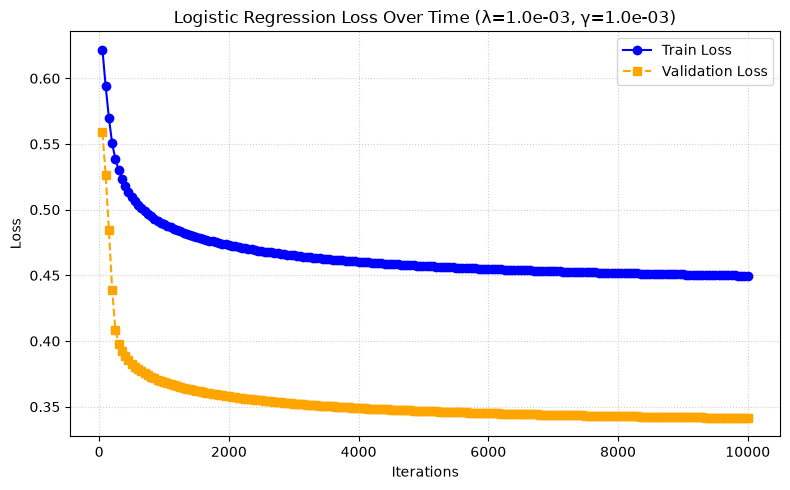

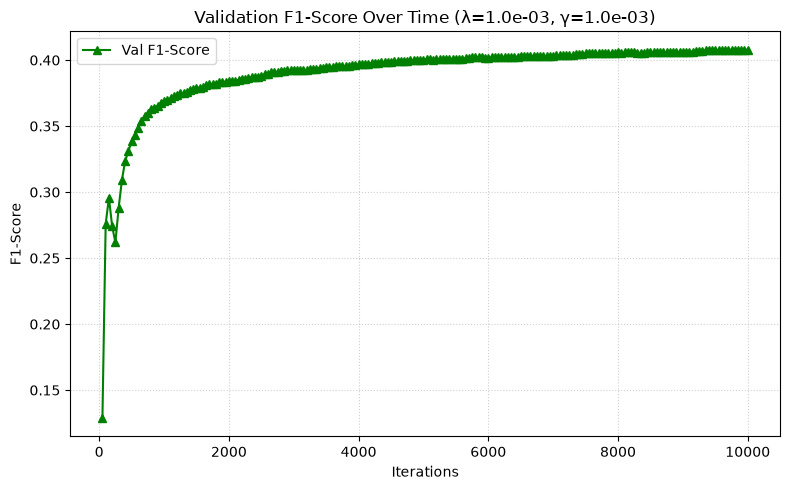

In [ ]:
iterations = list(range(checkpoint, max_iters + 1, checkpoint))

# ---------------------------------------------------------
# Figure 1: Train Loss vs. Validation Loss Over Time
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(iterations, train_losses, label="Train Loss", marker="o", color="blue")
plt.plot(
    iterations,
    val_losses,
    label="Validation Loss",
    marker="s",
    color="orange",
    linestyle="--",
)

plt.title(
    f"Regularized Logistic Regressione (lambda={lambda_:.1e}, gamma={gamma:.1e})"
)
plt.xlabel("Iterations")
plt.ylabel("Negative Log Likelihood")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Figure 2: Validation F1-Score Over Time
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(iterations, f1_scores, label="Val F1-Score", marker="^", color="green")

plt.title(f"Validation F1-Score (lambda={lambda_:.1e}, gamma={gamma:.1e})")
plt.xlabel("Iterations")
plt.ylabel("F1-Score")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
predict = sigmoid(np.matmul(x_test, log_reg_model))
predict[predict >= 0.5] = 1
predict[predict < 0.5] = -1

create_csv_submission(test_ids, y_pred=predict, name="test.csv")

In [21]:
print(np.unique(predict, return_counts=True))
print(len(predict[predict == 1]))
print(len(predict[predict == -1]))

(array([-1.,  1.]), array([81423, 27956]))
27956
81423


### Logistic Regressions with hyperparam selection

In [ ]:
tx_train = add_bias(x_train)
tx_train_split, tx_val_split, y_train_split, y_val_split = train_val_split(tx_train, y_train, val_ratio=0.2, seed=42)

lambda_values = np.logspace(-4, 1, 6)
gamma_values = np.logspace(-4, -2, 5)
n_lambdas = len(lambda_values)
n_gammas = len(gamma_values)

checkpoint = 50
max_iters = 1000
num_checkpoints = max_iters // checkpoint

train_losses = np.zeros((n_lambdas, n_gammas, num_checkpoints))
val_losses = np.zeros((n_lambdas, n_gammas, num_checkpoints))

for i, lambda_ in enumerate(lambda_values):
    for j, gamma in enumerate(gamma_values):
        print(f"Training model with lambda={lambda_} and gamma={gamma}")
        w = np.zeros((tx_train_split.shape[1]))

        for ckp_idx, iteration in enumerate(range(checkpoint, max_iters + 1, checkpoint)):
            w, train_loss = reg_logistic_regression(
                y_train_split,
                tx_train_split,
                lambda_,
                w,
                checkpoint,
                gamma,
            )

            train_losses[i, j, ckp_idx] = train_loss
            val_losses[i, j, ckp_idx] = negative_log_likelihood(y_val_split, tx_val_split, w)



Training model with lambda=0.0001 and gamma=0.0001
Training model with lambda=0.0001 and gamma=0.00031622776601683794
Training model with lambda=0.0001 and gamma=0.001
Training model with lambda=0.0001 and gamma=0.0031622776601683794
Training model with lambda=0.0001 and gamma=0.01
Training model with lambda=0.0001 and gamma=0.03162277660168379


c:\Users\fpb25\Documents\Programmierprojekte\ML-project1\implementations.py:165: RuntimeWarning: divide by zero encountered in log
  return -np.mean(y * np.log(pred) + (1 - y) * np.log(1 - pred))
c:\Users\fpb25\Documents\Programmierprojekte\ML-project1\implementations.py:165: RuntimeWarning: invalid value encountered in multiply
  return -np.mean(y * np.log(pred) + (1 - y) * np.log(1 - pred))


Training model with lambda=0.0001 and gamma=0.1


c:\Users\fpb25\Documents\Programmierprojekte\ML-project1\implementations.py:146: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-t))


Training model with lambda=0.001 and gamma=0.0001
Training model with lambda=0.001 and gamma=0.00031622776601683794
Training model with lambda=0.001 and gamma=0.001
Training model with lambda=0.001 and gamma=0.0031622776601683794
Training model with lambda=0.001 and gamma=0.01
Training model with lambda=0.001 and gamma=0.03162277660168379
Training model with lambda=0.001 and gamma=0.1
Training model with lambda=0.01 and gamma=0.0001
Training model with lambda=0.01 and gamma=0.00031622776601683794
Training model with lambda=0.01 and gamma=0.001
Training model with lambda=0.01 and gamma=0.0031622776601683794
Training model with lambda=0.01 and gamma=0.01
Training model with lambda=0.01 and gamma=0.03162277660168379
Training model with lambda=0.01 and gamma=0.1
Training model with lambda=0.1 and gamma=0.0001
Training model with lambda=0.1 and gamma=0.00031622776601683794
Training model with lambda=0.1 and gamma=0.001
Training model with lambda=0.1 and gamma=0.0031622776601683794
Training 

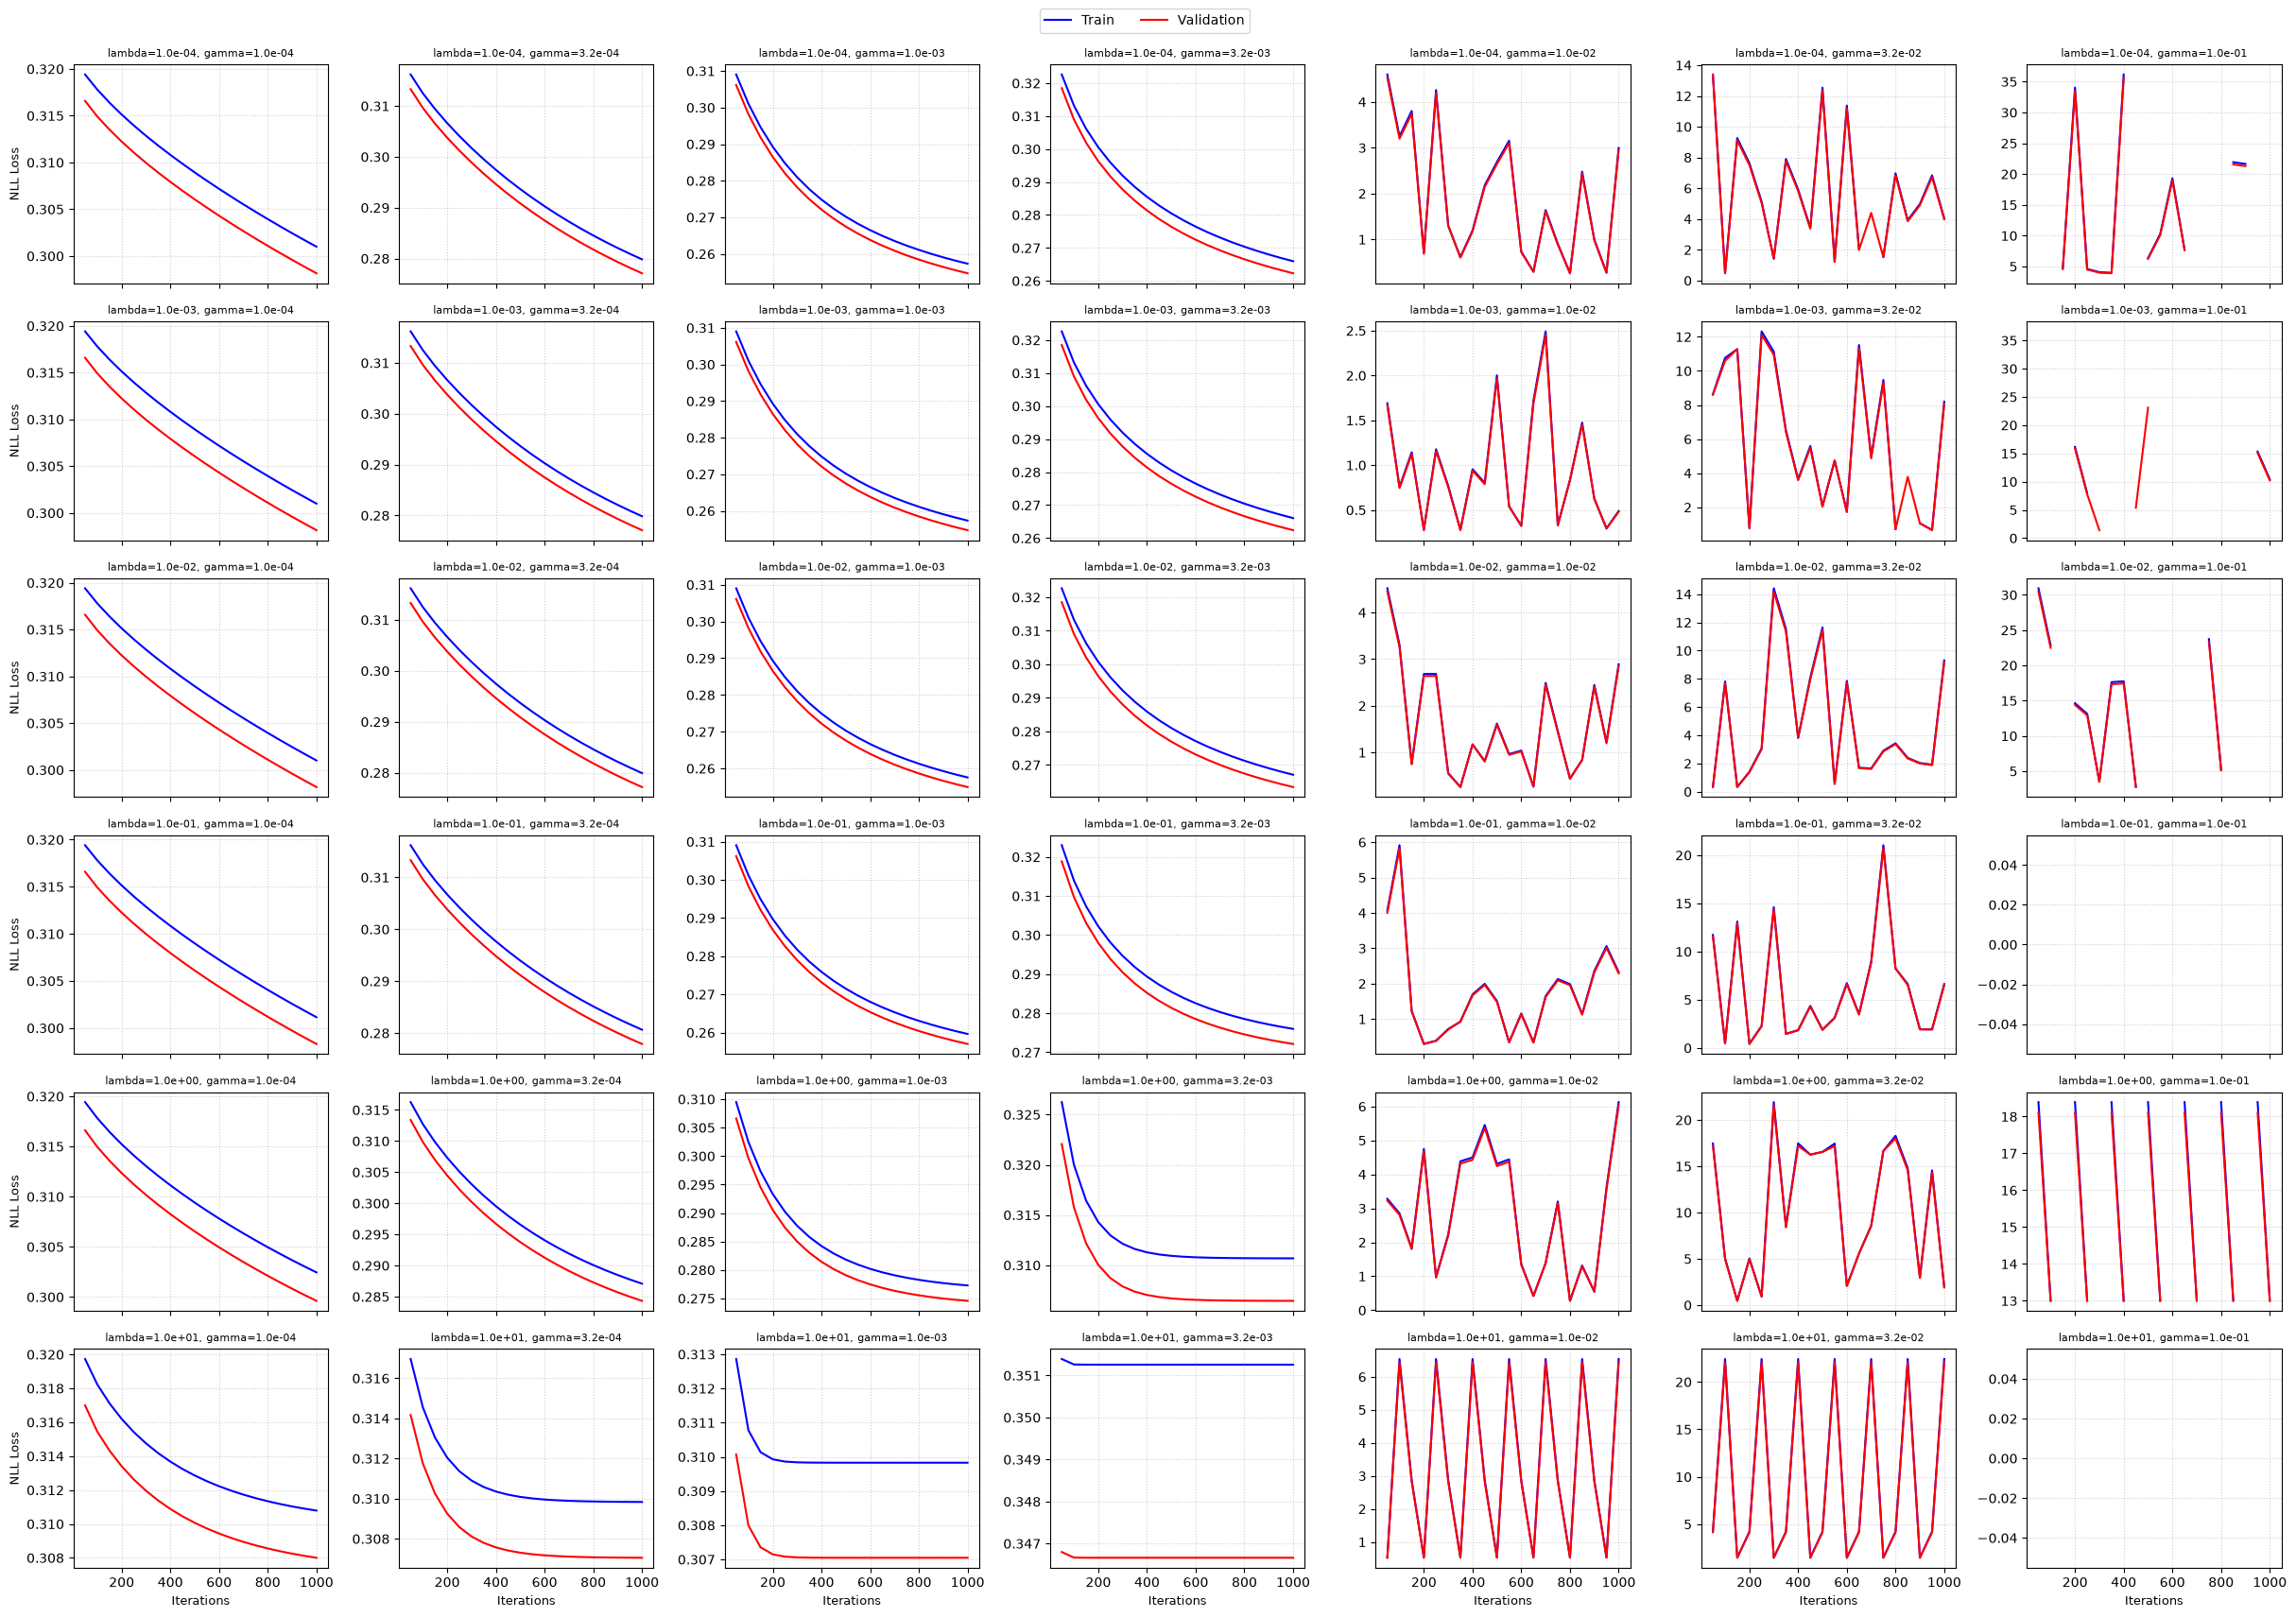

In [31]:
iterations = np.arange(checkpoint, max_iters + 1, checkpoint)

# Create a grid of subplots (rows: lambda, cols: gamma)
fig, axes = plt.subplots(
    n_lambdas, n_gammas, figsize=(n_gammas * 3.5, n_lambdas * 2.8), sharex=True, sharey=False
)

for i, lambda_ in enumerate(lambda_values):
    for j, gamma in enumerate(gamma_values):
        ax = axes[i, j]

        # Plot train and val loss curves over iterations
        ax.plot(iterations, train_losses[i, j, :], label="Train", color="blue", linewidth=1.5)
        ax.plot(iterations, val_losses[i, j, :], label="Validation", color="red", linewidth=1.5)
        # Annotate each subplot with hyperparameter values
        ax.set_title(f"lambda={lambda_:.1e}, gamma={gamma:.1e}", fontsize=8)
        ax.grid(True, linestyle=":", alpha=0.6)

# Label outer axes to avoid clutter
for ax in axes[-1, :]:
    ax.set_xlabel("Iterations", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("NLL Loss", fontsize=9)

# Add a single shared legend for the whole grid
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02), fontsize=10)

plt.tight_layout()
plt.show()

### Support Vector Machines

In [8]:
train_split_x, val_split_x, train_split_y, val_split_y = train_val_split(x_train, y_train, val_ratio=0.2, seed=42)
train_split_y[train_split_y==0] = -1
val_split_y[val_split_y==0] = -1

Final training accuracy = 91.15 %
Training time: 132.7 seconds 


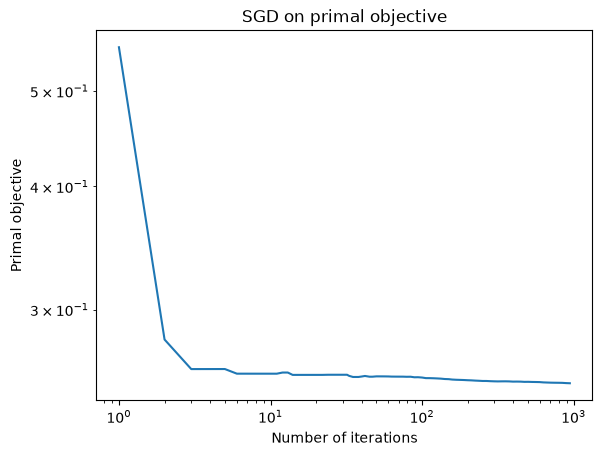

0.9126426623188627


In [ ]:
losses, w = sgd_for_svm_demo(train_split_y, train_split_x, 1000)
print(accuracy_from_model(val_split_y, val_split_x, w))

In [11]:
predict = val_split_x @ w
predict[predict >= 0] = 1
predict[predict < 0] = -1
print(f1_score(val_split_y, predict, pos_label=1))

0.0


In [ ]:
print("Distribution of predicted classes:")
print(len(predict[predict == 1]))
print(len(predict[predict == -1]))

print("Distribution of actual classes:")
print(len(val_split_y[val_split_y == 1]))
print(len(val_split_y[val_split_y == -1]))

5733
59894


Final training accuracy = 67.31 %
Training time: 32.4 seconds 


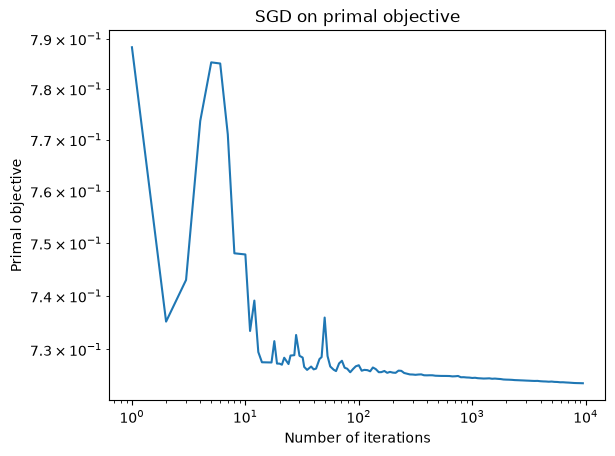

0.9126426623188627
0.0


In [ ]:
tx_train = add_bias(x_train)
y_train[y_train == 0] = -1

tx_train_split, tx_val_split, y_train_split, y_val_split = train_val_split(tx_train, y_train, val_ratio=0.2, seed=42)

tx_train_balanced, y_train_balanced = balance_dataset(tx_train_split, y_train_split, balance_number=5, seed=42)
losses, w_200 = sgd_for_svm_demo(y_train_balanced, tx_train_balanced, 10_000)

print(accuracy_from_model(y_val_split, tx_val_split, w_200))

predict = tx_val_split @ w_200
predict[predict >= 0] = 1
predict[predict < 0] = -1
print(f1_score(y_val_split, predict, pos_label=1))

In [30]:
# 1. Inspect the magnitudes of feature weights vs bias
print("Max feature weight magnitude:", np.max(np.abs(w_200[:-1])))
print("Bias value:", w_200[-1])

# 2. Inspect the range of raw decision scores before taking the sign
raw_scores = tx_val_split @ w_200
print("Score range:", raw_scores.min(), "to", raw_scores.max())

Max feature weight magnitude: 0.006411465696898099
Bias value: 1.394992408437797e-05
Score range: -1.5678161681604617 to -0.09869904670798457


In [28]:
print("Distribution of predicted classes:")
print("Pos class 1:", len(predict[predict == 1]))
print("Neg class -1", len(predict[predict == -1]))

print("Distribution of actual classes:")
print("Pos class 1:", len(y_val_split[y_val_split == 1]))
print("Neg class -1", len(y_val_split[y_val_split == -1]))

print("Distribution of actual classes in the training data:")
print("Pos class 1:", len(y_train_balanced[y_train_balanced == 1]))
print("Neg class -1", len(y_train_balanced[y_train_balanced == -1]))

Distribution of predicted classes:
Pos class 1: 0
Neg class -1 65627
Distribution of actual classes:
Pos class 1: 5733
Neg class -1 59894
Distribution of actual classes in the training data:
Pos class 1: 23242
Neg class -1 47853


In [51]:
predict = x_test@w_200
predict[predict >= 0] = 1
predict[predict < 0] = -1
create_csv_submission(test_ids, y_pred=predict, name="test_svm.csv")